# So sánh model local · 24/10/2026

**Ngữ pháp:** Qwen3-0.6B gốc, Qwen + Grammar LoRA và CoEdIT-large. **Phát âm:** wav2vec2 B, XLS-R TIMIT và CROTTC-IF.

Notebook chỉ đọc kết quả đã lưu; không tải model, không train, không gọi API hay dùng GPU. Nếu một arm chưa xong hoặc identity không khớp, cell kiểm tra sẽ dừng thay vì tạo số liệu thiếu.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Markdown, Image, HTML
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from scripts.report_model_comparison import load_bundle, grammar_rows, pronunciation_rows, case_rows, NAMES
OUT = ROOT / 'data/generated/model-comparison-20261024'
bundle = load_bundle(OUT)
display(Markdown('**Đã xác minh đầy đủ các arm, cùng case và hash bằng chứng.**'))
display(pd.DataFrame([{'file': name, 'sha256': sha} for name, sha in bundle['input_sha256'].items()]))

**Đã xác minh đầy đủ các arm, cùng case và hash bằng chứng.**

,file,sha256
0,grammar\qwen-base\predictions.jsonl,3aae15f7cfacb9c9ec957bcad854ac62edcdb5075e24f6...
1,grammar\qwen-base\metadata.json,cd418bcb0eb549d1bdd2c518a005878aa3fb94aa6cbea5...
2,grammar\qwen-grammar\predictions.jsonl,f2c4955b59c0e200720f468c85624873fe0aa1726c495c...
3,grammar\qwen-grammar\metadata.json,1d65129eb3badd59d62e3b48cd40938fc8c4cc21c745e5...
4,grammar\coedit-large\predictions.jsonl,8164f3a01979e6d9a4a36a7dd71abdc41b9f3a11baffd6...
5,grammar\coedit-large\metadata.json,7f833613851335f1ed5a70206d2f3541f2eb6d71c201d2...
6,grammar\manifest.json,9a457aa874eb2f58a34b88a42a3b133a932526925857ec...
7,grammar\summary.json,d4e92a618badb8e2f242896aeabe8e750db2ed7a520307...
8,pronunciation\manifest.json,dd9634f72d6c72fcd9e0597b52b6127e9953c514adfeef...
9,pronunciation\results.json,124d1a6a5244461e919710384f51b5f6dfba99eaa6b1b6...


In [2]:
from scripts.report_model_comparison import key_findings
display(Markdown('## Kết quả lượt thử\n\n' + '\n\n'.join(key_findings(bundle))))

## Kết quả lượt thử

Sửa ngữ pháp · cùng 100 câu: GLEU toàn bộ câu/source fallback CoEdIT 70.91, Qwen + Grammar LoRA 69.53; chênh lệch CoEdIT − LoRA +1.38 điểm. Native output có sẵn: CoEdIT 100/100, LoRA 100/100.

Diễn đạt tự nhiên · cùng 100 câu: GLEU toàn bộ câu/source fallback CoEdIT 57.05, Qwen + Grammar LoRA 55.16; chênh lệch CoEdIT − LoRA +1.90 điểm. Native output có sẵn: CoEdIT 100/100, LoRA 100/100.

Phụ hậu kiểm định dạng · sửa ngữ pháp: GLEU nội dung toàn bộ câu/source fallback Qwen gốc 56.35 → LoRA 69.53 (+13.18 điểm). Đây là trích nguyên chuỗi từ schema khác được phát hiện sau khi xem output; không thay kết quả native và không chứng minh độ chính xác ngữ pháp.

Phụ hậu kiểm định dạng · diễn đạt tự nhiên: GLEU nội dung toàn bộ câu/source fallback Qwen gốc 38.48 → LoRA 55.16 (+16.68 điểm). Đây là trích nguyên chuỗi từ schema khác được phát hiện sau khi xem output; không thay kết quả native và không chứng minh độ chính xác ngữ pháp.

Luồng giao kết quả · Grammar LoRA: guard chặn 87/200 đầu ra native, trong đó 14 đầu ra khớp ít nhất một tham chiếu công bố (chỉ chuẩn hóa khoảng trắng). Điều này cho thấy một phần gợi ý tham chiếu hợp lệ bị chặn; không chứng minh tất cả 87 gợi ý bị chặn đều đúng.

wav2vec2 B local · 120 audio: phone F1 target gốc 49.1%. Gợi ý từ theo full39: FPR trên phần khả dụng 21.4%, coverage 100.0%; recall trên toàn bộ lỗi từ chuyên gia 56.6%.

XLS-R 300M · TIMIT · 120 audio: phone F1 target gốc 40.6%. Gợi ý từ theo full39: FPR trên phần khả dụng 40.6%, coverage 100.0%; recall trên toàn bộ lỗi từ chuyên gia 72.2%.

CROTTC-IF · 120 audio: phone F1 target gốc 19.7%. Gợi ý từ theo full39: FPR trên phần khả dụng 43.2%, coverage 92.1%; recall trên toàn bộ lỗi từ chuyên gia 71.8%.

Các số trên là phép thử local trên subset cố định. GLEU đo khớp tham chiếu; native availability đo contract. Gợi ý phát âm chưa calibration. Không suy ra model thắng ở mọi tình huống và chưa đổi model mặc định trong demo.

## 1. Sửa ngữ pháp và diễn đạt tự nhiên

100 câu W&I và 100 câu JFLEG official test, chọn bằng hash trước khi suy luận; bỏ trùng lexical tìm được trong nguồn train/validation công khai. Đây là subset đã từng quan sát, không phải benchmark mù mới.

Tách **native availability** khỏi chất lượng câu. GLEU toàn bộ câu dùng **fallback giữ nguyên nguồn** khi native output không hợp lệ. GLEU valid-only có mẫu số khác giữa model; không xếp hạng ngang hàng bằng cột đó. GLEU/chrF/exact-match là diagnostic tham chiếu, không phải độ chính xác ngữ pháp hay đánh giá tự nhiên bởi người. Không có điểm ERRANT trong phép thử này. Control lexical bỏ khác biệt hoa/thường và dấu câu khi tìm nguồn trùng tham chiếu; giữ nguyên exact là diagnostic bảo thủ, không phải độ chính xác giữ câu đã đúng.

,task,model,rows,native_available_rate,delivery_gleu,valid_only_gleu,valid_only_rows,controls_preserved_lexical,mean_seconds
0,grammar_corrected,copy-source,100,1.0,54.3413,54.3413,100,NaN,NaN
1,grammar_corrected,qwen-base,100,0.0,54.3413,NaN,0,0.0,2.321263
2,grammar_corrected,qwen-grammar,100,1.0,69.5277,69.5277,100,39.0,2.543149
3,grammar_corrected,coedit-large,100,1.0,70.9065,70.9065,100,35.0,0.975417
4,natural,copy-source,100,1.0,37.5822,37.5822,100,NaN,NaN
5,natural,qwen-base,100,0.0,37.5822,NaN,0,0.0,2.303017
6,natural,qwen-grammar,100,1.0,55.1579,55.1579,100,22.0,1.999165
7,natural,coedit-large,100,1.0,57.0544,57.0544,100,17.0,1.217566


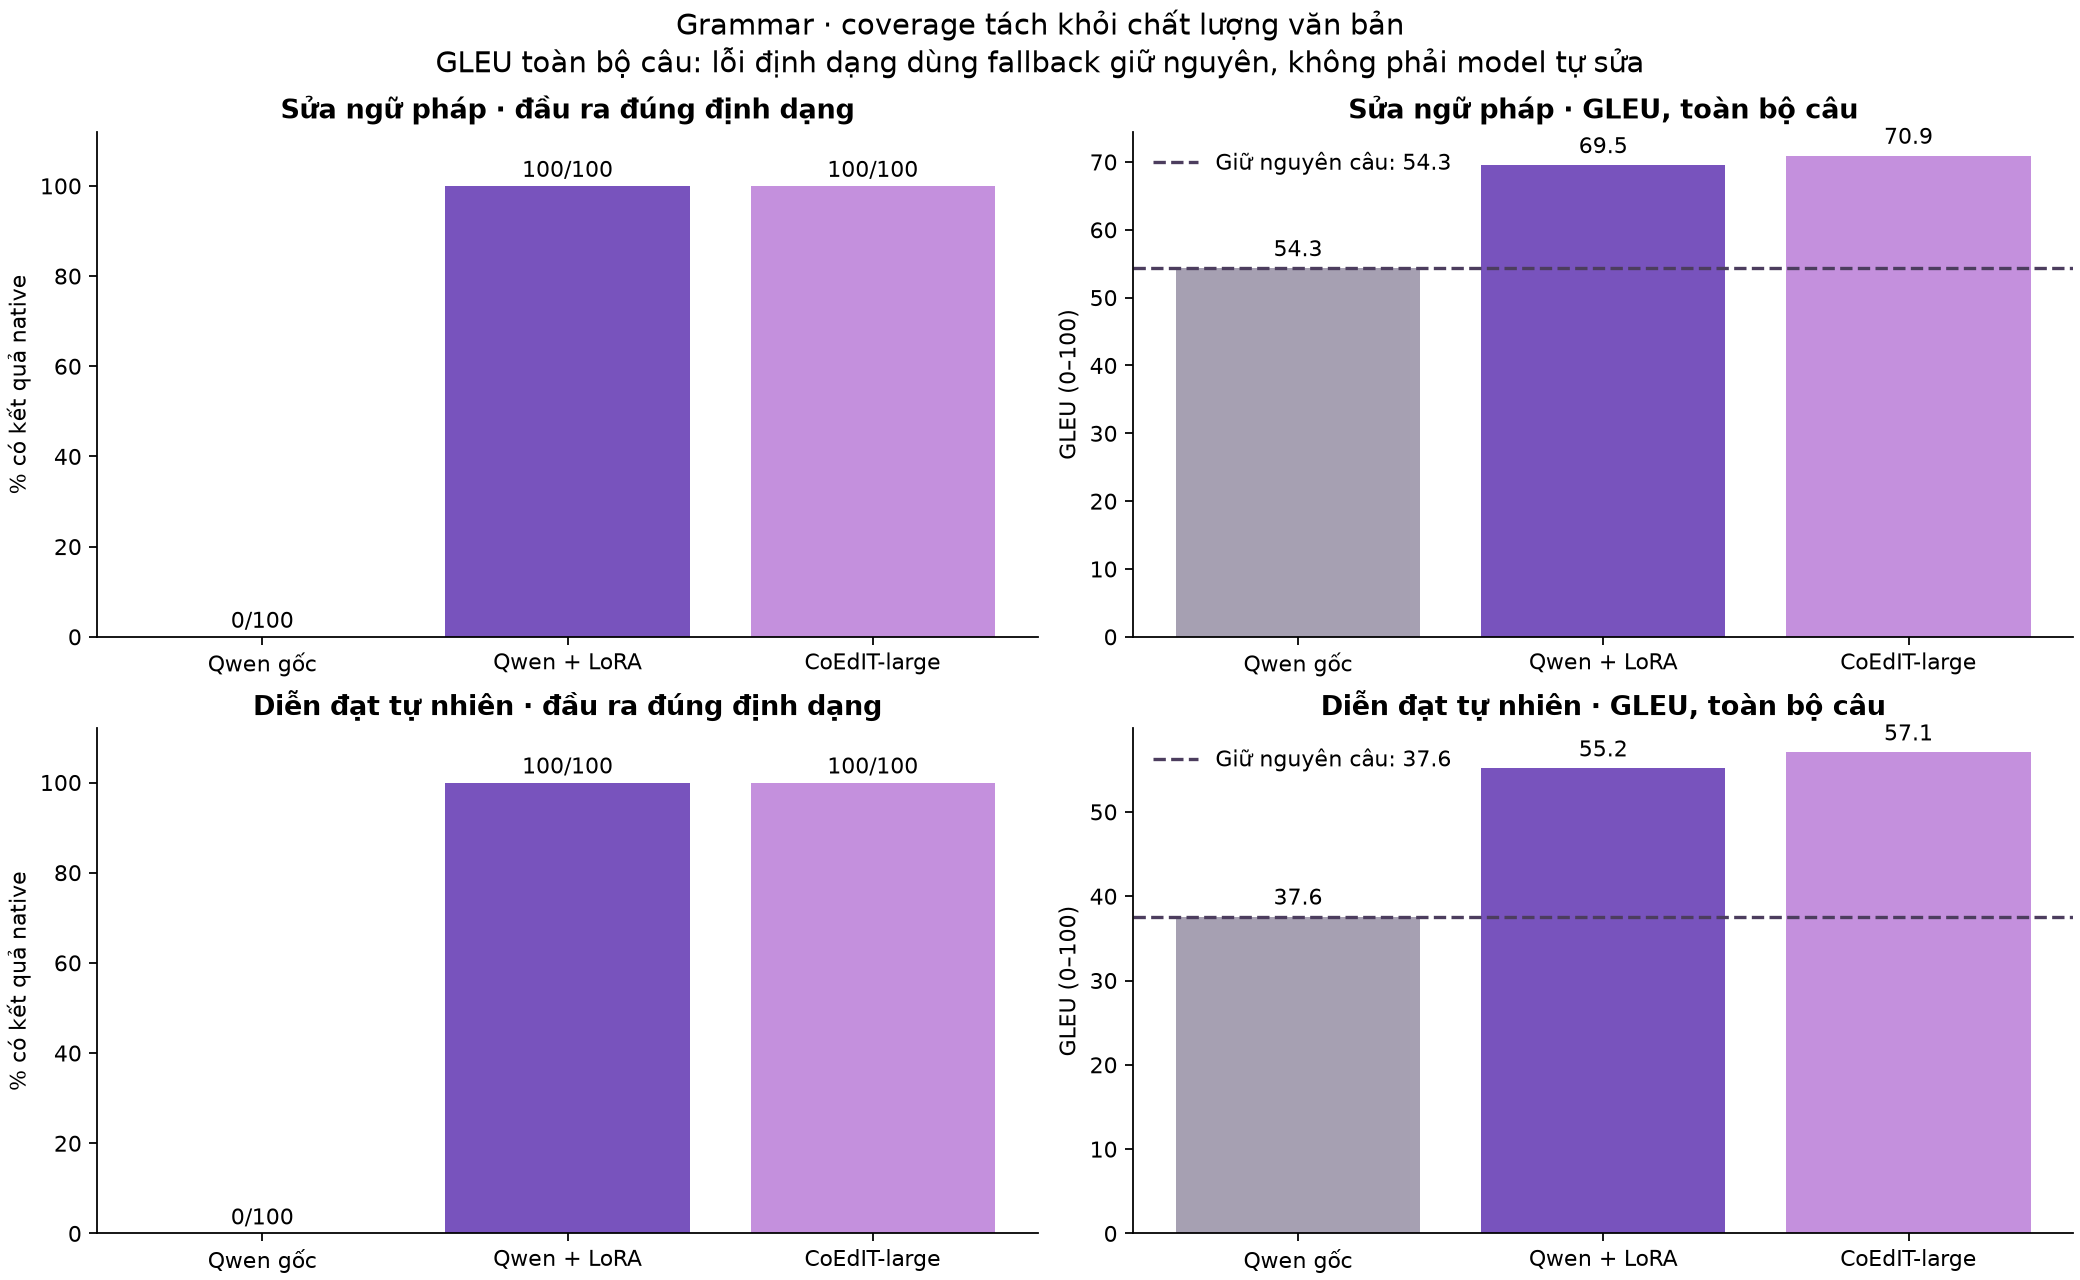

**Loại trùng trước chọn mẫu:** {"coedit_train_or_validation_source_or_target": 662}

**Giới hạn:** W&I internal heldout comes from published training corpus; unknown private CoEdIT training or near-duplicates remain possible. Exact lexical overlap removed against Qwen training/validation and public CoEdIT training/validation source/target. JFLEG official test is a stronger heldout benchmark, but base pretraining contamination is unknown. No human semantic or naturalness judgments. Development examples excluded from published metric aggregates.

In [3]:
grammar = pd.DataFrame(grammar_rows(bundle))
display(grammar.filter(items=['task', 'model', 'rows', 'native_available_rate', 'delivery_gleu', 'valid_only_gleu', 'valid_only_rows', 'controls_preserved_lexical', 'mean_seconds']))
display(Image(filename=str(OUT / 'grammar_diagnostics.png')))
display(Markdown('**Loại trùng trước chọn mẫu:** ' + json.dumps(bundle['grammar_manifest']['dataset']['excluded'], ensure_ascii=False)))
display(Markdown('**Giới hạn:** ' + ' '.join(bundle['grammar_manifest']['limitations'])))

## 2. Phát âm: phát hiện lỗi và báo nhầm

120 audio có nhãn chuyên gia, 20 câu cho mỗi 6 speaker. Model nhận waveform không có transcript chuẩn. **Original inventory** giữ nguyên ký hiệu gốc, gồm distortion, là strict target của dự án. Full39 bỏ stress/distortion nhưng giữ sự kiện lỗi chuyên gia, có thể làm một số contrast không còn biểu diễn được. Common37 là **tác vụ giảm inventory**: gộp AO→AA, ZH→SH, DX→T, AX→AH và bỏ những substitution chuyên gia không còn phân biệt được; không thay thế original target/full39.

Phone F1 dùng scorer của dự án, không tái lập trực tiếp F1 trên paper. Word review dùng cùng aligner biến thể dictionary cho cả ba model, chưa phải kết luận đã calibration. Recall/FPR **available-only** chỉ tính phần tạo được gợi ý; recall **all expert errors** tính cả lỗi ở phần không khả dụng. Xem đồng thời mẫu số, coverage, lỗi/từ đúng không khả dụng và số quyết định calibration.

,model,inventory,cases,precision,recall,f1,per,review_false_positive_rate_available_only,review_recall_all_expert_errors,review_coverage
0,cascade-B,research_original_inventory,120,0.486312,0.495082,0.490658,0.167787,0.214489,0.566161,1.00000
1,cascade-B,research_full39,120,0.490164,0.490164,0.490164,0.163555,0.214489,0.566161,1.00000
2,cascade-B,research_common37,120,0.488411,0.495798,0.492077,0.161314,0.213184,0.561947,1.00000
3,timit-xlsr-300m,research_original_inventory,120,0.320683,0.554098,0.406250,0.269604,0.406250,0.722343,1.00000
4,timit-xlsr-300m,research_full39,120,0.320683,0.554098,0.406250,0.265870,0.406250,0.722343,1.00000
5,timit-xlsr-300m,research_common37,120,0.334006,0.556303,0.417402,0.247697,0.380084,0.710177,1.00000
6,crottc-if,research_original_inventory,120,0.131667,0.388525,0.196680,0.466517,0.432348,0.718004,0.92103
7,crottc-if,research_full39,120,0.131667,0.388525,0.196680,0.462036,0.432348,0.718004,0.92103
8,crottc-if,research_common37,120,0.131065,0.394958,0.196817,0.459547,0.428571,0.723451,0.92103


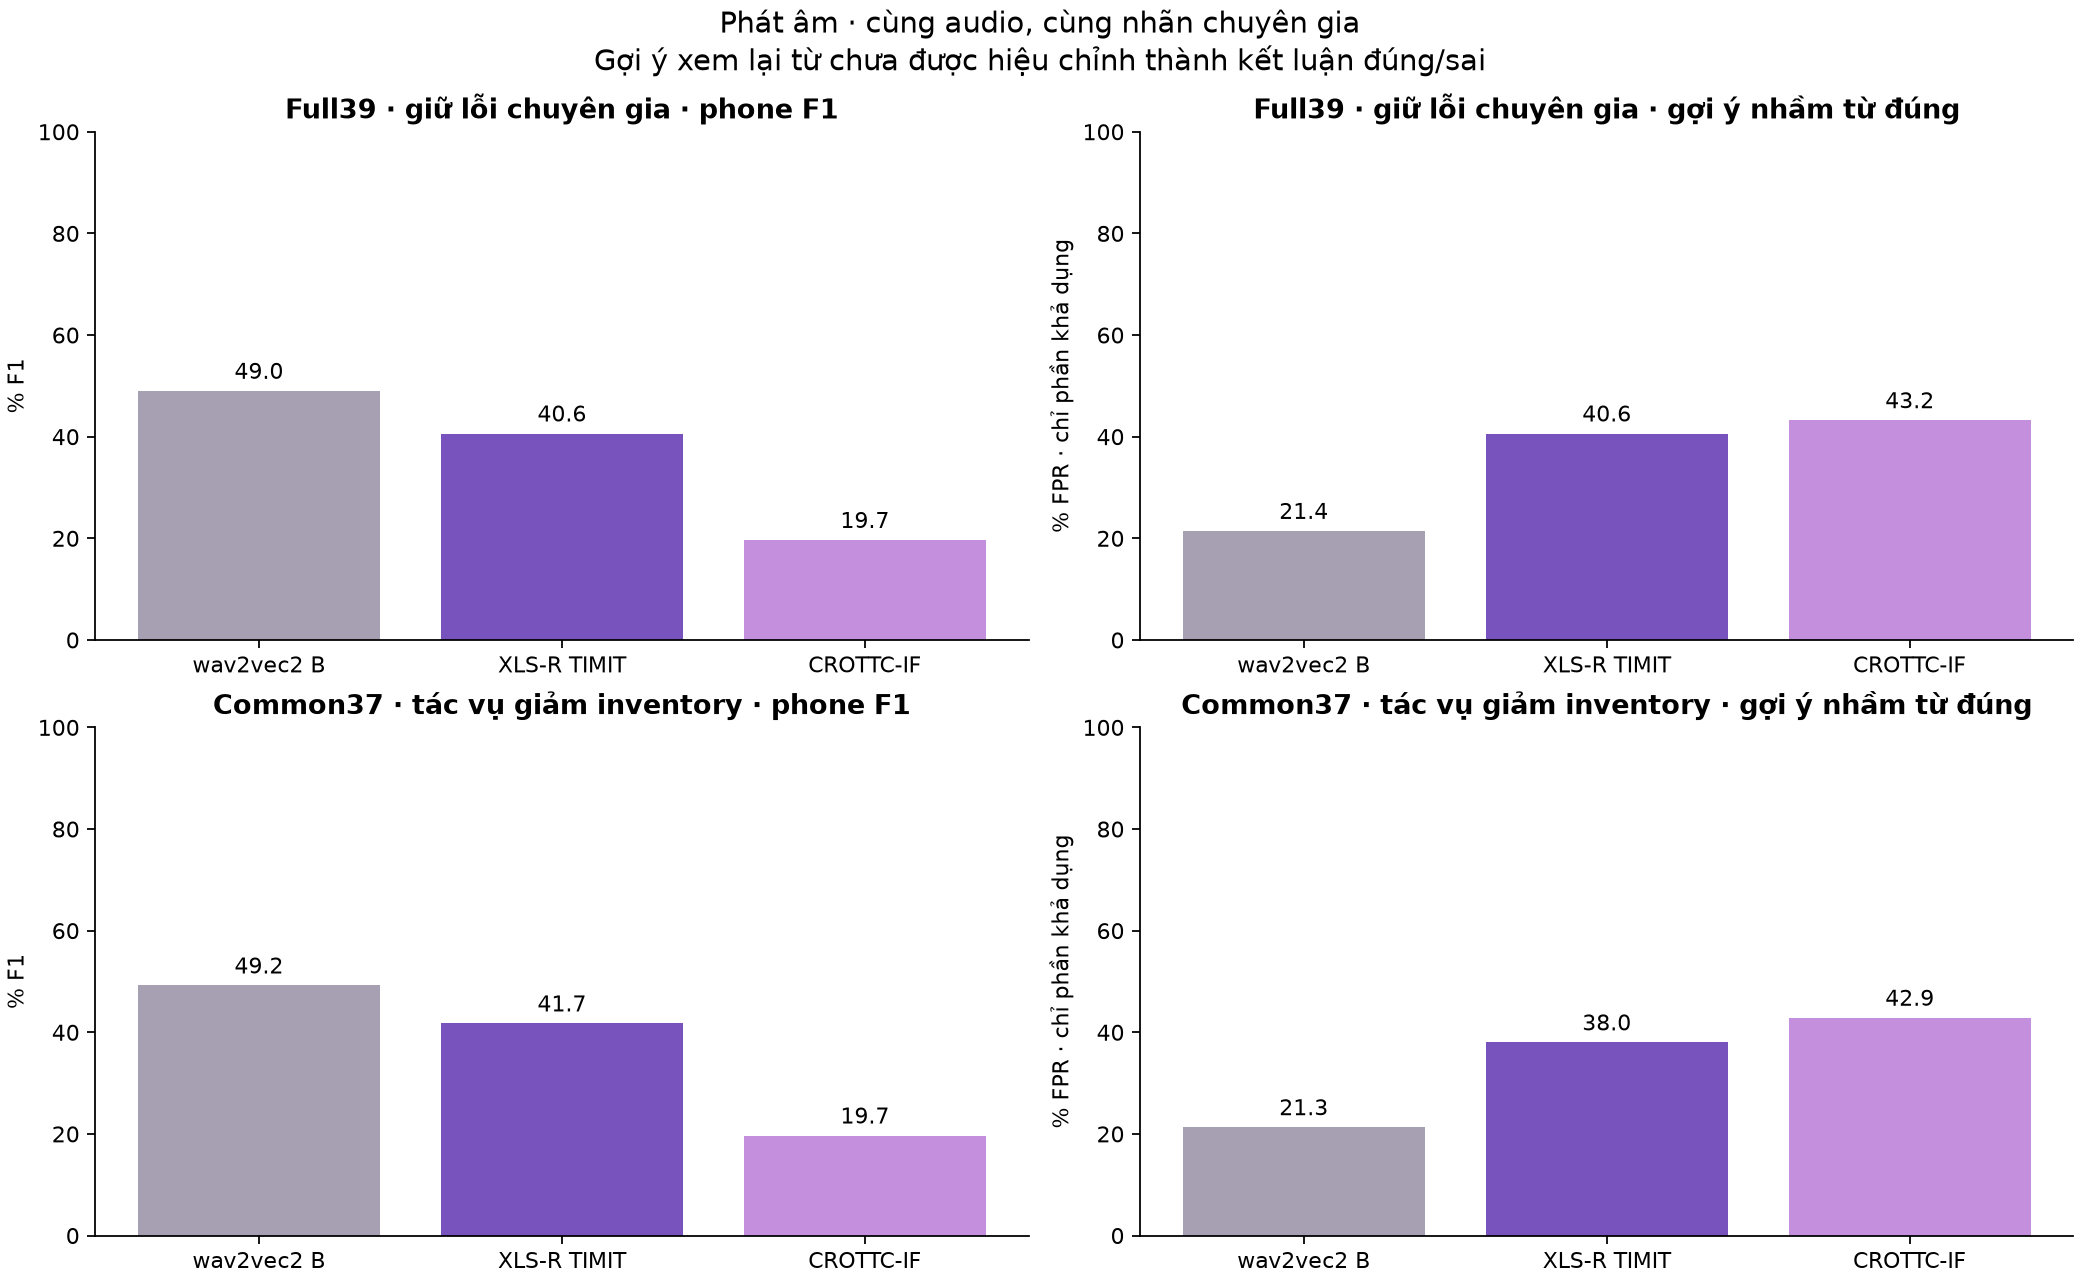

**Thời gian:** inference riêng từng model; thiết bị/precision/fallback ghi trong bảng và raw JSON. Không suy ra tốc độ toàn luồng từ số này.

In [4]:
pronunciation = pd.DataFrame(pronunciation_rows(bundle))
display(pronunciation.filter(items=['model', 'inventory', 'cases', 'precision', 'recall', 'f1', 'per', 'review_false_positive_rate_available_only', 'review_recall_all_expert_errors', 'review_coverage']))
display(Image(filename=str(OUT / 'pronunciation_diagnostics.png')))
display(Markdown('**Thời gian:** inference riêng từng model; thiết bị/precision/fallback ghi trong bảng và raw JSON. Không suy ra tốc độ toàn luồng từ số này.'))

,speaker,native_languages,model,cases,precision,recall,f1,per,review_false_positive_rate_available_only,review_recall_available_only,review_recall_all_expert_errors,review_coverage,review_unavailable_error_words,review_unavailable_correct_words
1,NJS,Spanish,cascade-B,20,0.432099,0.360825,0.393258,0.146405,0.206612,0.432099,0.432099,1.000000,0,0
4,NJS,Spanish,timit-xlsr-300m,20,0.240223,0.443299,0.311594,0.261438,0.471074,0.641975,0.641975,1.000000,0,0
7,NJS,Spanish,crottc-if,20,0.156627,0.268041,0.197719,0.247059,0.317308,0.635135,0.580247,0.881188,7,17
10,TLV,Vietnamese,cascade-B,20,0.734694,0.692308,0.712871,0.188822,0.279412,0.751825,0.751825,1.000000,0,0
13,TLV,Vietnamese,timit-xlsr-300m,20,0.567460,0.687500,0.621739,0.315710,0.367647,0.832117,0.832117,1.000000,0,0
16,TLV,Vietnamese,crottc-if,20,0.191330,0.615385,0.291904,0.942598,0.609375,0.946970,0.912409,0.956098,5,4
19,TNI,Hindi,cascade-B,20,0.343434,0.404762,0.371585,0.173529,0.291339,0.485294,0.485294,1.000000,0,0
22,TNI,Hindi,timit-xlsr-300m,20,0.225806,0.500000,0.311111,0.291176,0.511811,0.779412,0.779412,1.000000,0,0
25,TNI,Hindi,crottc-if,20,0.112821,0.261905,0.157706,0.325000,0.389831,0.705882,0.705882,0.953846,0,9
28,TXHC,Chinese,cascade-B,20,0.330508,0.487500,0.393939,0.195815,0.240000,0.655738,0.655738,1.000000,0,0


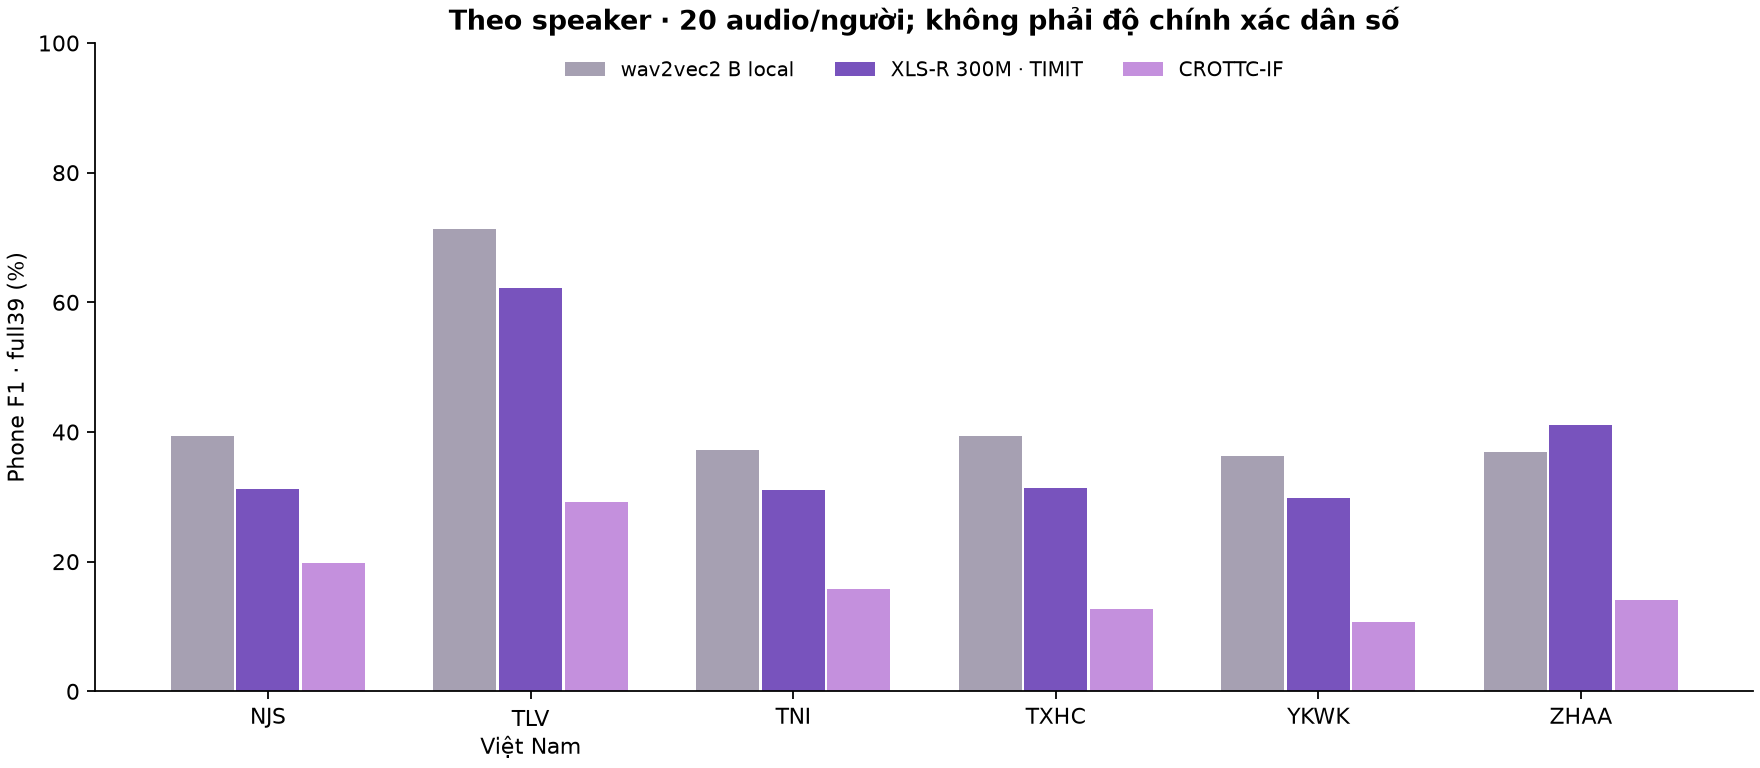

**TLV:** metadata xác nhận Vietnamese; đây chỉ là 20 câu của một người Việt. Tổng 120 audio không chứng minh độ chính xác trên dân số người Việt.

In [5]:
speaker = pd.DataFrame(pronunciation_rows(bundle, by_speaker=True))
display(speaker[speaker.inventory == 'research_full39'][['speaker','native_languages','model','cases','precision','recall','f1','per','review_false_positive_rate_available_only','review_recall_available_only','review_recall_all_expert_errors','review_coverage','review_unavailable_error_words','review_unavailable_correct_words']])
display(Image(filename=str(OUT / 'pronunciation_by_speaker.png')))
display(Markdown('**TLV:** metadata xác nhận Vietnamese; đây chỉ là 20 câu của một người Việt. Tổng 120 audio không chứng minh độ chính xác trên dân số người Việt.'))

In [6]:
cases = pd.DataFrame(case_rows(bundle))
development = cases[cases.cohort == 'user_development']
display(development[['domain','id','task','model','source','prediction','error','seconds']])
display(Markdown('**Ví dụ phát triển không có nhãn độc lập:** không tính accuracy/semantic score/F1 cho các câu hoặc audio này. Xem raw output và gợi ý từng từ trong báo cáo HTML.'))

,domain,id,task,model,source,prediction,error,seconds
200,grammar,development:usually:grammar_corrected,grammar_corrected,qwen-base,i usually wakes up at seven am then i brush my...,None,invalid_schema,2.617159
201,grammar,development:usually:natural,natural,qwen-base,i usually wakes up at seven am then i brush my...,None,invalid_schema,2.493145
202,grammar,development:yesterday:grammar_corrected,grammar_corrected,qwen-base,"Yesterday I wake up at 7, I no brush teeth and...",None,invalid_schema,3.690217
203,grammar,development:yesterday:natural,natural,qwen-base,"Yesterday I wake up at 7, I no brush teeth and...",None,invalid_schema,3.428842
204,grammar,development:profession:grammar_corrected,grammar_corrected,qwen-base,Currently I am a software engineer.,None,invalid_schema,1.689020
205,grammar,development:profession:natural,natural,qwen-base,Currently I am a software engineer.,None,invalid_schema,1.553777
206,grammar,development:coffee:grammar_corrected,grammar_corrected,qwen-base,I would like to order a cup of coffee and one ...,None,invalid_schema,2.170059
207,grammar,development:coffee:natural,natural,qwen-base,I would like to order a cup of coffee and one ...,None,invalid_schema,2.072171
208,grammar,development:garbled:grammar_corrected,grammar_corrected,qwen-base,I will wi to order a cupf coffee and one ice t...,None,invalid_schema,2.037971
209,grammar,development:garbled:natural,natural,qwen-base,I will wi to order a cupf coffee and one ice t...,None,invalid_schema,1.963818


**Ví dụ phát triển không có nhãn độc lập:** không tính accuracy/semantic score/F1 cho các câu hoặc audio này. Xem raw output và gợi ý từng từ trong báo cáo HTML.

In [7]:
audit = bundle['delivery_audit']
if audit:
    guard_rows = [{'model': arm, 'cohort': cohort, 'task': task, **row} for arm, model in audit['models'].items() for cohort, group in model['summary'].items() for task, row in group.items()]
    display(pd.DataFrame(guard_rows))
    display(Markdown(' '.join(audit['limitations'])))
else:
    display(Markdown('Chưa có saved-output delivery audit; không suy luận model đã tích hợp vào demo.'))

,model,cohort,task,rows,native_available,delivered,lexical_changes_delivered,format_only_changes_delivered,reference_matching_native_outputs,reference_matching_outputs_withheld,reasons
0,qwen-base,published_heldout,grammar_corrected,100,0,0,0,0,0,0,{'native_contract_unavailable': 100}
1,qwen-base,published_heldout,natural,100,0,0,0,0,0,0,{'native_contract_unavailable': 100}
2,qwen-base,user_development,grammar_corrected,8,0,0,0,0,0,0,{'native_contract_unavailable': 8}
3,qwen-base,user_development,natural,8,0,0,0,0,0,0,{'native_contract_unavailable': 8}
4,qwen-grammar,published_heldout,grammar_corrected,100,100,68,11,6,45,7,"{'lexical_guard_withheld': 32, 'accepted': 68}"
5,qwen-grammar,published_heldout,natural,100,100,45,14,5,33,7,"{'lexical_guard_withheld': 55, 'accepted': 45}"
6,qwen-grammar,user_development,grammar_corrected,8,8,7,3,1,0,0,"{'accepted': 7, 'lexical_guard_withheld': 1}"
7,qwen-grammar,user_development,natural,8,8,7,3,1,0,0,"{'accepted': 7, 'lexical_guard_withheld': 1}"
8,coedit-large,published_heldout,grammar_corrected,100,100,60,12,11,35,6,"{'accepted': 60, 'lexical_guard_withheld': 40}"
9,coedit-large,published_heldout,natural,100,100,37,16,8,32,10,"{'lexical_guard_withheld': 63, 'accepted': 37}"


The benchmark's frozen generation budget differs from the production worker; this audits saved outputs, not a new live run. The lexical guard is a conservative delivery rule, not an independent semantic or grammatical correctness metric. Reference-matching output means exact equality after whitespace normalization with at least one published reference; this does not grade other unmatched suggestions as wrong. CoEdIT is audited with the same guard only as a compatibility diagnostic; it is not integrated into the demo. Each field is checked independently with the unmodified source in the other field, matching the production per-field guard.

In [8]:
from scripts.report_model_comparison import content_rows
content = content_rows(bundle)
if content:
    display(pd.DataFrame(content))
    display(Markdown('**Phân tích hậu kiểm định dạng:** Qwen gốc có thể sửa câu bên trong schema sai. Chỉ lấy nguyên nội dung trường transcript từ object task/transcript chính xác; không sửa chữ, không sinh lại. Quy tắc được đặt sau khi quan sát output ban đầu nên không thay thế kết quả native đã đóng băng và không đổi parser demo.'))
else:
    display(Markdown('Chưa có phân tích hậu kiểm nội dung; native availability không đồng nghĩa độ chính xác tiếng Anh.'))

,model,task,rows,content_available,native_content,posthoc_transcript_field,fallback_gleu,fallback_chrf,available_only_gleu,available_only_rows
0,qwen-base,grammar_corrected,100,99,0,99,56.3470,80.442754,57.9624,99
1,qwen-base,natural,100,100,0,100,38.4788,74.720485,38.4788,100
2,qwen-grammar,grammar_corrected,100,100,100,0,69.5277,89.385600,69.5277,100
3,qwen-grammar,natural,100,100,100,0,55.1579,90.705006,55.1579,100
4,coedit-large,grammar_corrected,100,100,100,0,70.9065,90.043867,70.9065,100
5,coedit-large,natural,100,100,100,0,57.0544,91.804163,57.0544,100


**Phân tích hậu kiểm định dạng:** Qwen gốc có thể sửa câu bên trong schema sai. Chỉ lấy nguyên nội dung trường transcript từ object task/transcript chính xác; không sửa chữ, không sinh lại. Quy tắc được đặt sau khi quan sát output ban đầu nên không thay thế kết quả native đã đóng băng và không đổi parser demo.

In [9]:
from scripts.report_model_comparison import SOURCES
display(Markdown('### Báo cáo và nguồn sơ cấp\n\n[Báo cáo HTML](../data/generated/model-comparison-20261024/report.html) · [CSV grammar](../data/generated/model-comparison-20261024/grammar_metrics.csv) · [CSV phát âm](../data/generated/model-comparison-20261024/pronunciation_metrics.csv)\n\n' + '\n'.join('- [' + title + '](' + url + ')' for title, url in SOURCES)))

### Báo cáo và nguồn sơ cấp

[Báo cáo HTML](../data/generated/model-comparison-20261024/report.html) · [CSV grammar](../data/generated/model-comparison-20261024/grammar_metrics.csv) · [CSV phát âm](../data/generated/model-comparison-20261024/pronunciation_metrics.csv)

- [CoEdIT · bài báo và model chính thức](https://aclanthology.org/2023.findings-emnlp.350/)
- [CoEdIT-large · Hugging Face](https://huggingface.co/grammarly/coedit-large)
- [Qwen3 · model chính thức](https://huggingface.co/Qwen/Qwen3-0.6B)
- [JFLEG · bài báo EACL 2017](https://aclanthology.org/E17-2037/)
- [JFLEG · dữ liệu và GLEU của tác giả](https://github.com/keisks/jfleg)
- [W&I+LOCNESS · BEA 2019](https://aclanthology.org/W19-4406/)
- [XLS-R TIMIT · model card của tác giả](https://huggingface.co/vitouphy/wav2vec2-xls-r-300m-timit-phoneme)
- [XLS-R · bài báo](https://arxiv.org/abs/2111.09296)
- [CROTTC-IF · bài báo](https://arxiv.org/abs/2604.22133)
- [CROTTC-IF · checkpoint chính thức](https://huggingface.co/Haopeng/CROTTC-IF-l2-arctic)
- [L2-ARCTIC · nguồn corpus](https://psi.engr.tamu.edu/l2-arctic-corpus/)
- [ERRANT · cách đánh giá GEC theo edit](https://aclanthology.org/P17-1074/)

## Lệnh tùy chọn · không được notebook tự chạy

Tạo lại báo cáo chỉ từ kết quả đã lưu:

```powershell
.venv\Scripts\python.exe -X utf8 scripts/report_model_comparison.py
```

Nếu chủ động muốn tiếp tục lượt đánh giá còn dở, chạy từng arm tuần tự trong terminal; các lệnh dưới **thực sự nạp model và dùng GPU**. Không chạy cùng training/demo trên GPU 4 GB. Manifest đã đóng băng; không đổi tham số hay prompt giữa các arm.

```powershell
.venv\Scripts\python.exe -X utf8 scripts/compare_grammar_models.py run --arm qwen-base
.venv\Scripts\python.exe -X utf8 scripts/compare_grammar_models.py run --arm qwen-grammar
.venv\Scripts\python.exe -X utf8 scripts/compare_grammar_models.py run --arm coedit-large
.venv\Scripts\python.exe -X utf8 scripts/compare_grammar_models.py summarize
.venv\Scripts\python.exe -X utf8 scripts/audit_grammar_delivery.py
.venv\Scripts\python.exe -X utf8 scripts/audit_grammar_content.py
.venv\Scripts\python.exe -X utf8 scripts/evaluate_pronunciation_models.py --output data/generated/model-comparison-20261024/pronunciation --run --resume --device cuda
.venv\Scripts\python.exe -X utf8 scripts/report_model_comparison.py
```